In [3]:

from ultralytics import YOLO

# Load pretrained YOLO11 nano model
model = YOLO("yolo11n.pt")

# Train the model using your corrected bounding boxes
results = model.train(
    data="data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    name="vial_detection"
)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/home/ad.msoe.edu/ostlera/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.183 🚀 Python-3.12.10 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14922MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, 

In [2]:
%pip install ultralytics

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 19.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 MB 128.6 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 876.6/876.6 kB 47.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 MB 118.7 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 554.6/554.6 MB 119.8 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 553.1/553.1 MB 96.8 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 131.3 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.0/216.0 MB 125.8 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 MB 110.7 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 130.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423

In [4]:
# Load the best trained model
model = YOLO("runs/detect/vial_detection/weights/best.pt")

# Evaluate on validation images
metrics = model.val(data="data.yaml")

print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.183 🚀 Python-3.12.10 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14922MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.1±0.0 ms, read: 144.7±27.7 MB/s, size: 66.2 KB)
val: Scanning /home/ad.msoe.edu/ostlera/labels/val.cache... 157 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 157/157 47.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 4.9it/s 2.1s.1ss
                   all        157        157      0.993      0.994      0.995      0.921
Speed: 1.6ms preprocess, 3.5ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to /home/ad.msoe.edu/ostlera/runs/detect/val
mAP50: 0.995
mAP50-95: 0.9206305791470127



image 1/1 /home/ad.msoe.edu/ostlera/images/train/vial_fill_20260923_184919_452807.jpg: 480x640 1 vial, 8.2ms
Speed: 0.9ms preprocess, 8.2ms inference, 1.5ms postprocess per image at shape (1, 3, 480, 640)


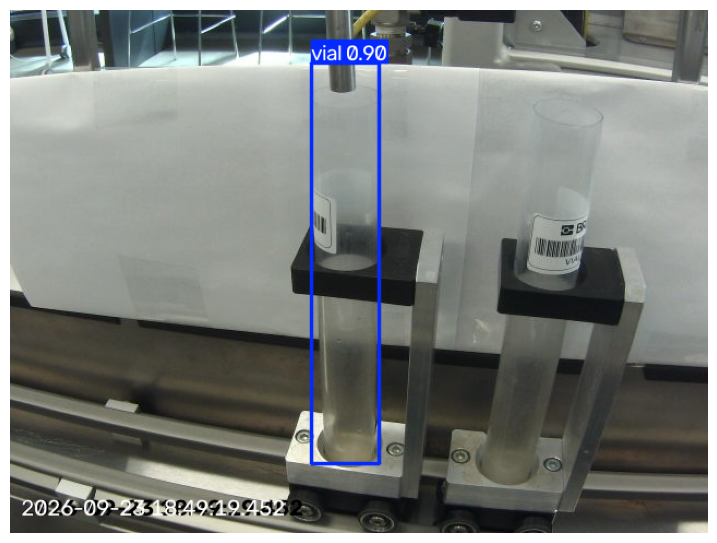

In [8]:
from ultralytics import YOLO
import matplotlib.pyplot as plt

model = YOLO("runs/detect/vial_detection/weights/best.pt")

# Predict bounding boxes on an image
results = model.predict(
    source="images/train/vial_fill_20260923_184919_452807.jpg",
    conf=0.5
)

# Display image with predicted bounding boxes
plt.figure(figsize=(9, 7))
plt.imshow(results[0].plot()[..., ::-1])
plt.axis("off")
plt.show()

In [10]:
from ultralytics import YOLO

model = YOLO("runs/detect/vial_detection/weights/best.pt")

model.predict(
    source="vial_fill_video_4.mp4",
    conf=0.5,
    save=True
)


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/9482) /home/ad.msoe.edu/ostlera/vial_fill_video_4.mp4: 480x640 1 vial, 9.9ms
video 1/1 (frame 2/9482) /home/ad.msoe.edu/ostlera/vial_fill_video_4.mp4: 480x640 1 vial, 18.3ms
video 1/1 (frame 3/9482) /home/ad.msoe.edu/ostlera/vial_fill_video_4.mp4: 480x640 1 vial, 14.8ms
video 1/1 (frame 4/9482) /home/ad.msoe.edu/ostlera/vial_fill_video_4.mp4: 480x640 1 vial, 13.2ms
video 1/1 (frame 5/9482) /home/ad.msoe.edu/ostlera/vial_fill_video_4.mp4

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 depth: None
 keypoints: None
 masks: None
 names: {0: 'vial'}
 obb: None
 orig_img: array([[[167, 144, 116],
         [217, 194, 166],
         [202, 184, 155],
         ...,
         [ 85,  90,  88],
         [ 85,  90,  88],
         [ 75,  80,  78]],
 
        [[161, 138, 110],
         [244, 221, 193],
         [207, 189, 160],
         ...,
         [ 85,  90,  88],
         [ 85,  90,  88],
         [ 75,  80,  78]],
 
        [[129, 118,  88],
         [201, 190, 160],
         [146, 140, 109],
         ...,
         [ 85,  90,  88],
         [ 85,  90,  88],
         [ 75,  80,  78]],
 
        ...,
 
        [[ 41,  49,  48],
         [ 41,  49,  48],
         [ 41,  49,  48],
         ...,
         [203, 224, 223],
         [203, 224, 223],
         [203, 224, 223]],
 
        [[ 41,  49,  48],
         [ 41,  49,  48],
         [ 41,  49,  48],
         ...,
       

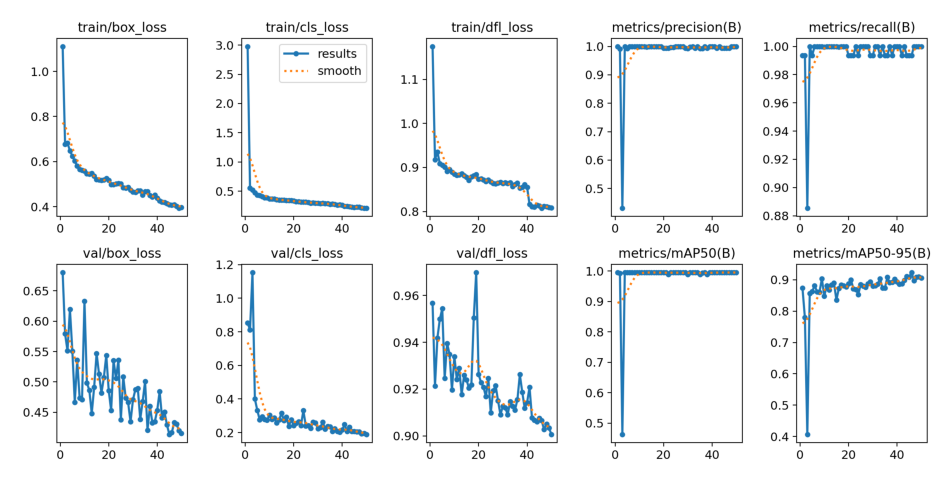

In [12]:
from PIL import Image
import matplotlib.pyplot as plt

image = Image.open("runs/detect/vial_detection/results.png")

plt.figure(figsize=(12, 7))
plt.imshow(image)
plt.axis("off")
plt.show()